In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model 

I0000 00:00:1793721102.611540  320942 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793721102.642498  320942 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793721103.327455  320942 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


<h1> Basic MLP - "standard" - normalising inputs and outputs using StandardScaler() 

<h3>Importing The Data

,Unnamed: 0,point,time,x,y,x_rb,y_rb,s0,s1,s2,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
0,0.0,0.0,1.272000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
1,1.0,1.0,2.699900,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
2,2.0,0.0,23.035400,1.2,1.2,1.200032,1.2,6144.0,-8393.0,2249.0,...,72.0,6.0,-60.0,-68.0,220.0,212.0,-214.0,-188.0,1.945455,1.709091
3,3.0,1.0,25.126699,1.1,1.2,1.099897,1.2,6144.0,-7949.0,1805.0,...,76.0,6.0,-46.0,-64.0,234.0,216.0,-200.0,-184.0,1.818182,1.672727
4,4.0,2.0,27.201900,1.0,1.2,0.999989,1.2,6144.0,-7506.0,1362.0,...,76.0,6.0,-32.0,-64.0,248.0,216.0,-186.0,-184.0,1.690909,1.672727


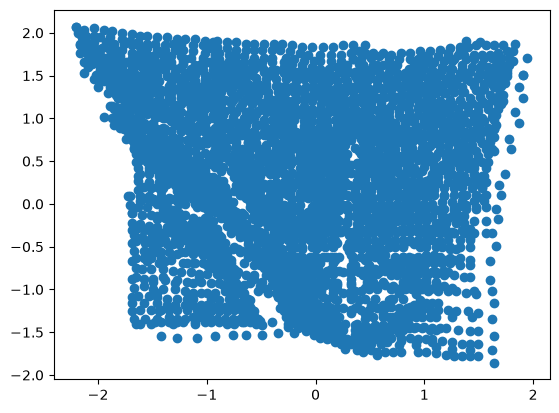

In [38]:
data_concat = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
display(data_concat.head())
plt.scatter(data_concat["cx_mm"], data_concat["cy_mm"])

<h3>Correcting The Data - Removing NANs

In [35]:
data_concat.isna().sum()

Unnamed: 0        0
point             0
time              0
x                 0
y                 0
x_rb              0
y_rb              0
s0                0
s1                0
s2                0
strain            0
frame_id          0
n_circles         0
cx              133
cy              133
radius          133
detected          0
track_cx          2
track_cy          2
track_radius      2
roi_x_min         2
roi_y_min         2
roi_x_max         2
roi_y_max         2
cx_rel          133
cy_rel          133
cx_mm           133
cy_mm           133
dtype: int64

In [36]:
data_concat = data_concat.dropna()

In [37]:
print(data_concat["s1"].dtype)

float32


<h3>Basic MLP - Inverse 

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.metrics import r2_score

import tensorflow as tf
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

In [7]:
dataset = data_concat[["cx_mm", "cy_mm", "s0", "s1", "s2"]].reset_index(drop=True) #reset indexes as multiple datapoints combined
inputs = data_concat[["cx_mm", "cy_mm"]]
outputs = data_concat[["s0", "s1", "s2"]]

In [8]:
scalerX = StandardScaler().fit(inputs)
scalerY = StandardScaler().fit(outputs)

X_scaled = scalerX.transform(inputs)
y_scaled = scalerY.transform(outputs)

7.97914357956317e-18
-1.0638858106084226e-17
1.0
1.0


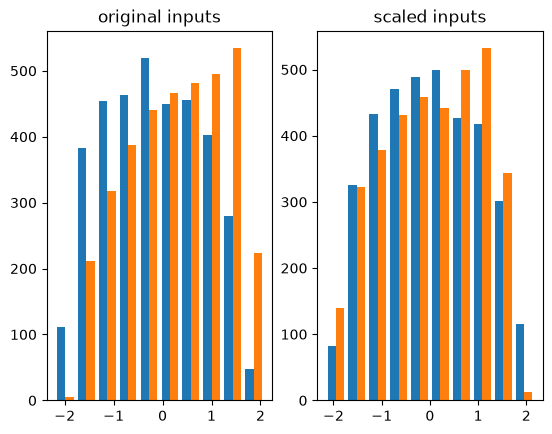

In [9]:
# print(scalerX.mean_)
fig, axs = plt.subplots(1,2)
axs[0].hist(inputs)
axs[0].set_title("original inputs")
axs[1].hist(X_scaled)
axs[1].set_title("scaled inputs")
print(X_scaled.mean())
print(y_scaled.mean())
print(X_scaled.std())
print(y_scaled.std())



In [10]:
print((X_scaled[:,0]))
print(max(X_scaled[:,0]))
print(max(X_scaled[:,1]))

[ 0.17209632  0.17209632  2.17135747 ... -1.36004771 -0.36975947
 -0.36975947]
2.171357469572096
1.8590249799558047


In [11]:
scalerX = StandardScaler().fit(inputs)
scalerY = StandardScaler().fit(outputs)

X_scaled = scalerX.transform(inputs)
y_scaled = scalerY.transform(outputs)

X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled = train_test_split(
    X_scaled, y_scaled, test_size=0.2, random_state=42
)

model = build_nn_model(X_train_scaled.shape[1], y_train_scaled.shape[1])
model.summary() #investigate

W0000 00:00:1793721103.896554  320942 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,531 (25.51 KB)

 Trainable params: 6,531 (25.51 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history = train_model(model, X_train_scaled, y_train_scaled, verbose=1)

Epoch 1/100


72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2614 - mae: 0.3554 - val_loss: 0.0196 - val_mae: 0.1081
Epoch 2/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0191 - mae: 0.0997 - val_loss: 0.0163 - val_mae: 0.0943
Epoch 3/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0180 - mae: 0.0939 - val_loss: 0.0161 - val_mae: 0.0919
Epoch 4/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0173 - mae: 0.0908 - val_loss: 0.0166 - val_mae: 0.0937
Epoch 5/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0169 - mae: 0.0886 - val_loss: 0.0154 - val_mae: 0.0889
Epoch 6/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0168 - mae: 0.0879 - val_loss: 0.0156 - val_mae: 0.0881
Epoch 7/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0167 - mae: 0.0875 - val_loss: 0.0151 - val_mae: 0.0851
Epoch 8/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0167 - mae: 0.0875 - val_loss: 0.0158 - val_mae: 0.0873
Epoch 9/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0165 - mae: 0.0

In [13]:
y_pred = model.predict(X_test_scaled, verbose=0)
evaluate_model("Neural Network", y_test_scaled, y_pred, is_scaled=True)


Neural Network Results (scaled):
  Overall R2:  0.9802
  Weighted R2: 0.9800


(0.9801556483107275, 0.9800267969672858)

<h2> Saving the model

In [33]:
model.save('models/16Oct_MLP_2_model.keras')

<h3> Evaluating the Model further

0.015327722765505314


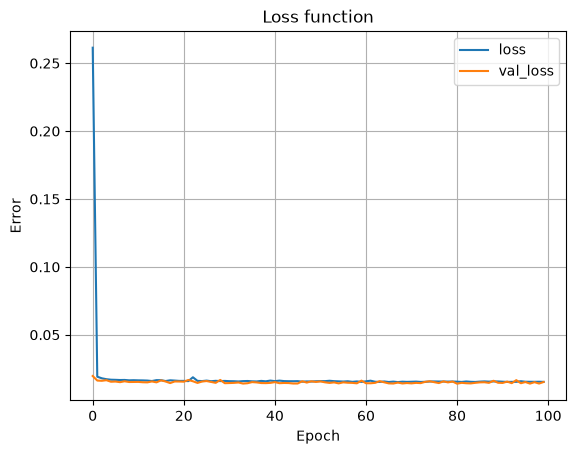

In [15]:
plot_loss(history)
print(history.history['loss'][-1])

0.08180557191371918


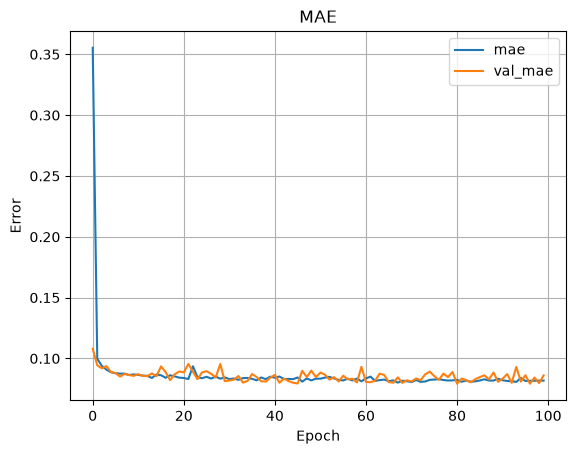

In [16]:
plot_mae(history)
print(history.history['mae'][-1])

In [17]:
test_results_dnn_standard = model.evaluate(X_test_scaled, y_test_scaled, verbose=0)
test_results_dnn_standard

[0.020489925518631935, 0.09056758880615234]

713 713


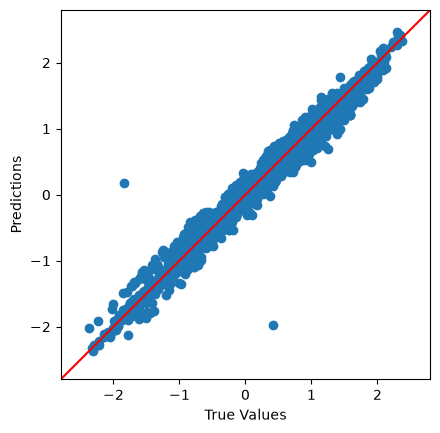

In [18]:
#make predictions with dnn model
#y_pred = model.predict(X_test_scaled, verbose=0)

a = plt.axes(aspect='equal')
plt.scatter(y_test_scaled, y_pred)
plt.xlabel('True Values')
plt.ylabel('Predictions')
lims = [-2.8, 2.8]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims, lims, color="red")
plt.title("")
print(len(y_test_scaled), len(y_pred))

Text(0.5, 0.98, '16th Oct Test Predictions not flattened')

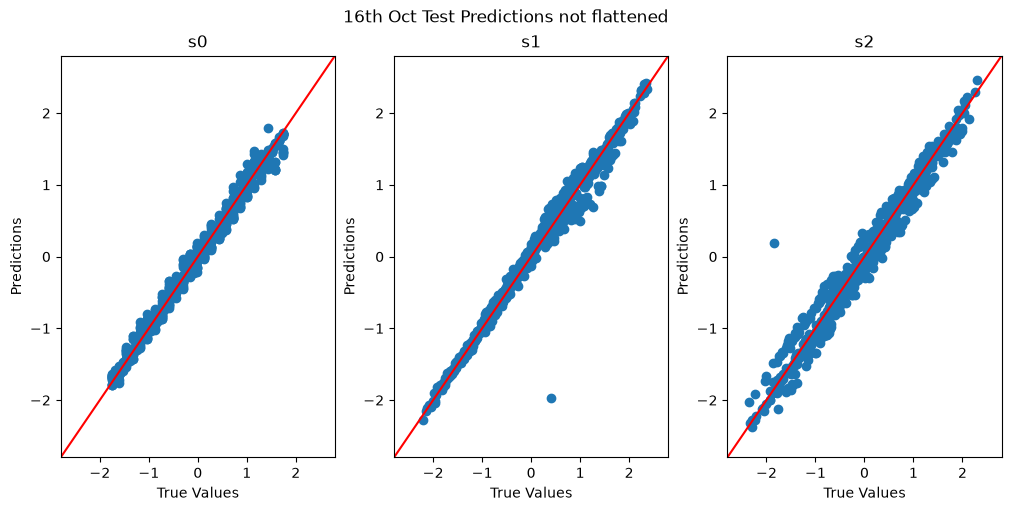

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(y_test_scaled[:, i], y_pred[:, i])
    lims = [-2.8, 2.8]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
fig.suptitle("16th Oct Test Predictions not flattened")

<h3> Look at the data transformed back to raw motor counts

In [20]:
y_pred_inverse = scalerY.inverse_transform(y_pred)
y_test_inverse = scalerY.inverse_transform(y_test_scaled)

713 713


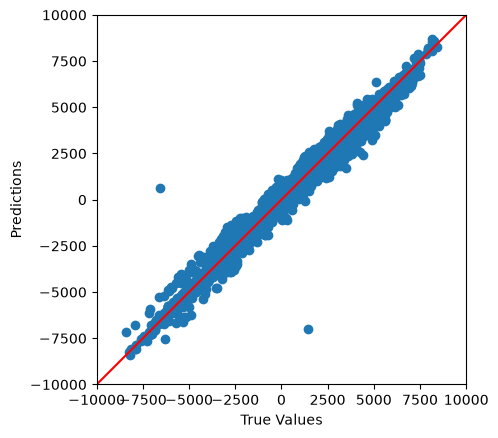

In [21]:
a = plt.axes(aspect='equal')
plt.scatter(y_test_inverse, y_pred_inverse)
plt.xlabel('True Values')
plt.ylabel('Predictions')
lims = [-10000, 10000]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims, lims, color="red")
plt.title("")
print(len(y_test_scaled), len(y_pred))

Text(0.5, 0.98, '16th Oct Test Predictions not flattened')

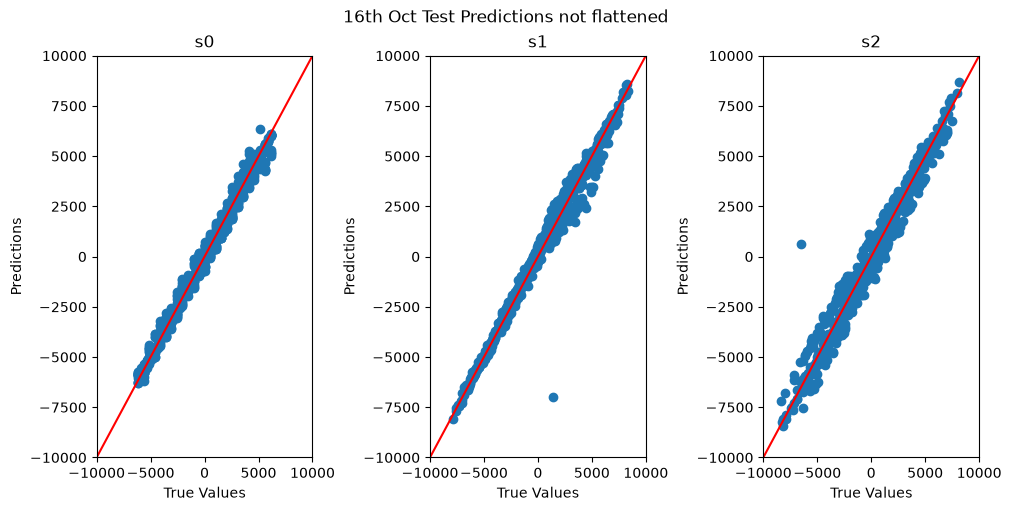

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(y_test_inverse[:, i], y_pred_inverse[:, i])
    lims = [-10000, 10000]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
fig.suptitle("16th Oct Test Predictions not flattened")

<h1> Testing with data from 27Oct - Dataset 2

In [39]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")
mesh0045_27Oct_nonans = mesh0045_27Oct.dropna()

input_27Oct_45 = mesh0045_27Oct_nonans[["cx_mm","cy_mm"]]
true_values_27Oct_45 = mesh0045_27Oct_nonans[["s0","s1","s2"]]

pred_27Oct_45_not_flat = model.predict(input_27Oct_45)

input_27Oct_45_scaled = scalerX.transform(mesh0045_27Oct_nonans[["cx_mm","cy_mm"]])
true_values_27Oct_45 = mesh0045_27Oct_nonans[["s0","s1","s2"]]
true_values_27Oct_45_scaled = scalerY.transform(true_values_27Oct_45)

pred_27Oct_45_scaled = model.predict(input_27Oct_45_scaled)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 822us/step


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 799us/step


Text(0.5, 0.98, 'Predictions on scan 0045_dmesh from 27Oct Dataset. Using NN trained on 16thOct Dataset')

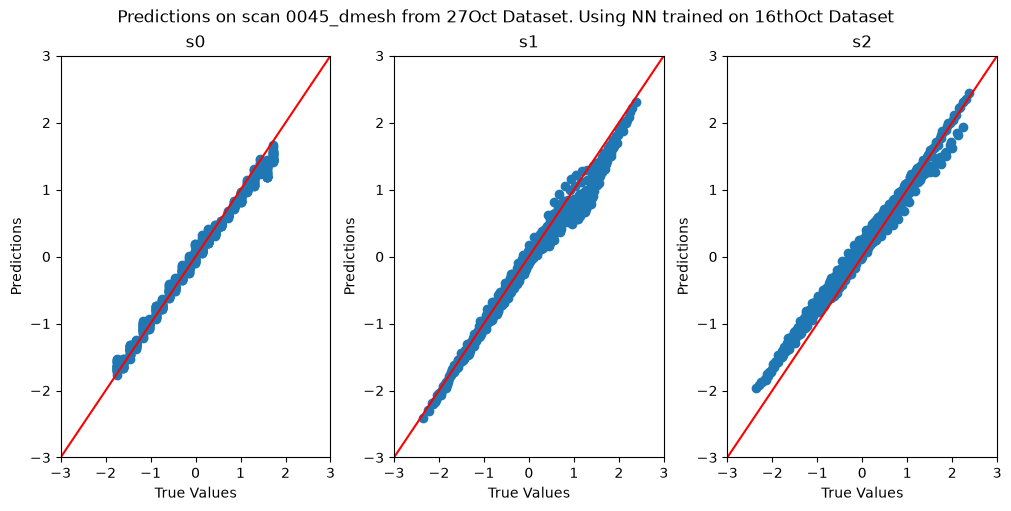

In [40]:
fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(true_values_27Oct_45_scaled[:, i],pred_27Oct_45_scaled[:, i])
    lims = [-3, 3]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
fig.suptitle("Predictions on scan 0045_dmesh from 27Oct Dataset. Using NN trained on 16thOct Dataset")

In [25]:
#evaluate with first scan of 27th Oct

evaluate_model("Standard NN Inverse on 27Oct Dataset 45", true_values_27Oct_45_scaled, pred_27Oct_45_scaled, is_scaled=True)



Standard NN Inverse on 27Oct Dataset 45 Results (scaled):
  Overall R2:  0.9728
  Weighted R2: 0.9728


(0.9727830861123579, 0.9728265921524379)

Text(0.5, 0.98, 'Predictions on scan 0045_dmesh from 27Oct Dataset. Using NN trained on 16thOct Dataset')

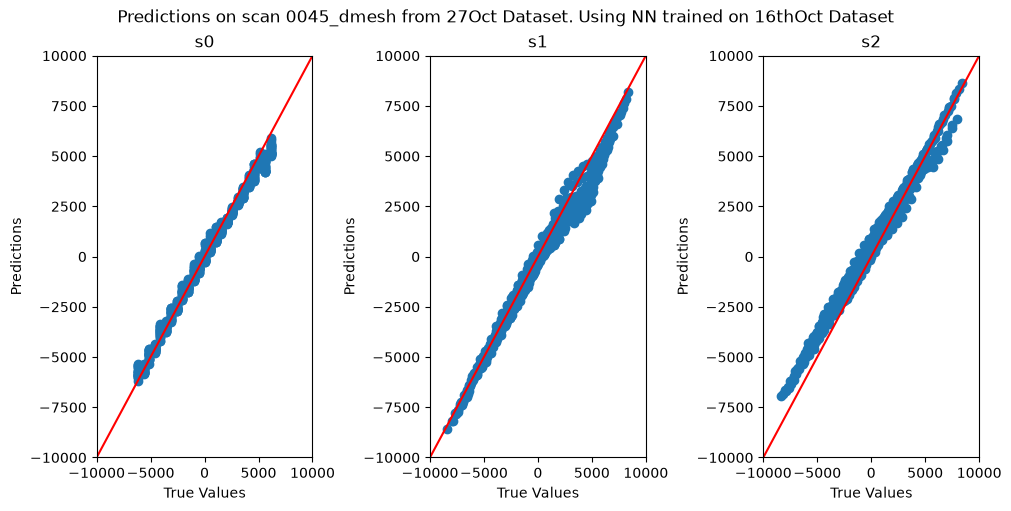

In [26]:
pred_27Oct_45 = scalerY.inverse_transform(pred_27Oct_45_scaled)

fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(true_values_27Oct_45[label], pred_27Oct_45[:, i])
    lims = [-10000, 10000]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
fig.suptitle("Predictions on scan 0045_dmesh from 27Oct Dataset. Using NN trained on 16thOct Dataset")

In [27]:
np.savetxt("16Oct_2_NN_Pred_27Oct_Scan0045_Scaled.csv", pred_27Oct_45, delimiter=',')

<h3> Try with all the data from 27th Oct?

<h2> Predicting for normal square - snake



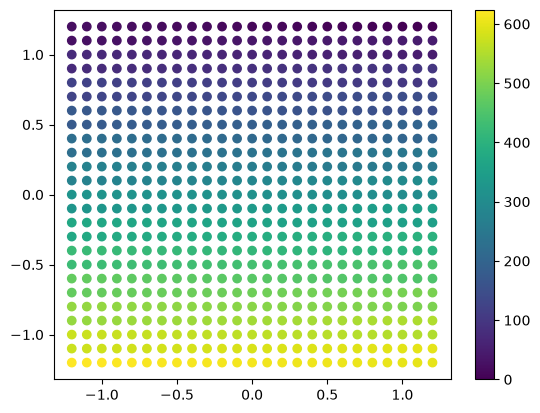

In [28]:
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
plt.colorbar()

In [29]:
snake_predictions = model.predict(mesh0045_27Oct[["x", "y"]])

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 809us/step


In [30]:
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)

In [31]:
print(snake_pred_inverse)
np.savetxt("predictions/16Oct_MLP_2_Pred_snake_mesh.csv", snake_pred_inverse, delimiter=',')

[[ 4722.503   -5562.666     921.90576]
 [ 4755.382   -5359.0107    657.8991 ]
 [ 4803.967   -5138.897     384.33002]
 ...
 [-4455.966    5993.4473  -1633.3027 ]
 [-4458.3643   6288.8647  -1913.8082 ]
 [-4499.6206   6600.5117  -2153.4653 ]]
